# 01 - Data inspection, cleaning, EDA and feature engineering

**Goal:** understand the data before modelling - shape, types, quality problems, class balance, how the classes differ, which features are useful - and prepare the cleaned data, engineered features and the train/validation/test split used by every later notebook.

**Outputs:** figures and tables in `artifacts/eda/`, `artifacts/data_sample.csv` (a small stratified sample used by the Streamlit app), and an `SDSS17-EDA` run in MLflow.

## 1. Setup

In [1]:
import sys, warnings, json
warnings.filterwarnings("ignore")
sys.path.insert(0, "../src")          # shared helpers live in src/common.py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mlflow
from common import (ROOT, ART, SEED, CLASSES, MAGS, COLORS, ID_COLS, SKY_COLS, FEATURE_SETS, PALETTE,
                    load_raw, clean, add_color_indices, make_splits, mlflow_experiment)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 140)

OUT = ART / "eda"; OUT.mkdir(parents=True, exist_ok=True)
def show(name):
    """Save the current figure into artifacts/eda and display it."""
    plt.tight_layout(); plt.savefig(OUT / name, dpi=130); plt.show()

## 2. Load and inspect
Shape, columns, data types, missing values, duplicates and class distribution - the basic health check.

In [2]:
raw = load_raw()
print("shape:", raw.shape)
display(raw.head())
display(raw.dtypes.to_frame("dtype").T)
print("missing values:", int(raw.isna().sum().sum()), "| duplicated rows:", int(raw.duplicated().sum()))
display(raw["class"].value_counts().to_frame("count").assign(share_pct=lambda d: (d["count"] / d["count"].sum() * 100).round(2)))

shape: (100000, 18)


,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,class,redshift,plate,MJD,fiber_ID
0,1.237661e+18,135.689107,32.494632,23.87882,22.27530,20.39501,19.16573,18.79371,3606,301,2,79,6.543777e+18,GALAXY,0.634794,5812,56354,171
1,1.237665e+18,144.826101,31.274185,24.77759,22.83188,22.58444,21.16812,21.61427,4518,301,5,119,1.176014e+19,GALAXY,0.779136,10445,58158,427
2,1.237661e+18,142.188790,35.582444,25.26307,22.66389,20.60976,19.34857,18.94827,3606,301,2,120,5.152200e+18,GALAXY,0.644195,4576,55592,299
3,1.237663e+18,338.741038,-0.402828,22.13682,23.77656,21.61162,20.50454,19.25010,4192,301,3,214,1.030107e+19,GALAXY,0.932346,9149,58039,775
4,1.237680e+18,345.282593,21.183866,19.43718,17.58028,16.49747,15.97711,15.54461,8102,301,3,137,6.891865e+18,GALAXY,0.116123,6121,56187,842


,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,class,redshift,plate,MJD,fiber_ID
dtype,float64,float64,float64,float64,float64,float64,float64,float64,int64,int64,int64,int64,float64,str,float64,int64,int64,int64


missing values: 0 | duplicated rows: 0


,count,share_pct
class,,
GALAXY,59445,59.44
STAR,21594,21.59
QSO,18961,18.96


**Reading:** 100,000 rows, no missing values, no duplicated rows, three imbalanced classes (galaxies are ~3x more frequent than quasars).
Because of the imbalance, accuracy alone would flatter a model that favours galaxies, so we track **Macro-F1** (the unweighted mean of per-class F1) as the main metric.

## 3. Data-quality checks
Two things deserve a closer look: SDSS's `-9999` placeholder and the repeated `obj_ID` values.

In [3]:
sentinels = {c: int((raw[c] == -9999).sum()) for c in MAGS}
print("-9999 sentinel counts:", sentinels)
display(raw.loc[(raw[MAGS] < -1000).any(axis=1), MAGS + ["redshift", "class"]])

dup = raw[raw["obj_ID"].duplicated(keep=False)]
print(f"\nrows whose obj_ID appears more than once: {len(dup):,} ({dup['obj_ID'].nunique():,} distinct IDs)")
print("repeated IDs whose rows have different photometry in column r:", int((dup.groupby("obj_ID")["r"].nunique() > 1).sum()),
      "of", dup["obj_ID"].nunique())
print("repeated IDs whose rows have different classes:", int((dup.groupby("obj_ID")["class"].nunique() > 1).sum()))

-9999 sentinel counts: {'u': 1, 'g': 1, 'r': 0, 'i': 0, 'z': 1}


,u,g,r,i,z,redshift,class
79543,-9999.0,-9999.0,18.1656,18.01675,-9999.0,0.000089,STAR



rows whose obj_ID appears more than once: 37,306 (15,359 distinct IDs)
repeated IDs whose rows have different photometry in column r: 15358 of 15359
repeated IDs whose rows have different classes: 5555


**Reading:**
* **`-9999`:** one object has -9999 in `u`, `g` and `z` - SDSS's code for "no measurement". It is a missing value disguised as a number and would wreck any distance- or scale-based method, so we **remove that row**. The rule needs no statistics from the data, therefore applying it *before* the split cannot leak anything.
* **Repeated `obj_ID`:** the IDs are 19-digit numbers stored as `float64`, which cannot represent them exactly, so different objects collide on the same value. The "duplicates" have different photometry and often different classes - they are **not** re-observations of one object, so they cannot leak between splits. `obj_ID` is an identifier and is excluded from the model inputs anyway.

## 4. Cleaning and feature engineering

In [4]:
df, n_removed = clean(raw)
df = add_color_indices(df)          # u-g, g-r, r-i, i-z
print(f"rows removed: {n_removed} -> {len(df):,} rows remain")
print("excluded identifier/metadata columns:", ID_COLS)
print("excluded sky-position columns:      ", SKY_COLS)
print("features WITH redshift:   ", FEATURE_SETS["with_redshift"])
print("features WITHOUT redshift:", FEATURE_SETS["without_redshift"])
display(df[["u", "g", "r", "i", "z", "u-g", "g-r", "r-i", "i-z", "redshift", "class"]].head())

rows removed: 1 -> 99,999 rows remain
excluded identifier/metadata columns: ['obj_ID', 'run_ID', 'rerun_ID', 'cam_col', 'field_ID', 'spec_obj_ID', 'plate', 'MJD', 'fiber_ID']
excluded sky-position columns:       ['alpha', 'delta']
features WITH redshift:    ['u', 'g', 'r', 'i', 'z', 'u-g', 'g-r', 'r-i', 'i-z', 'redshift']
features WITHOUT redshift: ['u', 'g', 'r', 'i', 'z', 'u-g', 'g-r', 'r-i', 'i-z']


,u,g,r,i,z,u-g,g-r,r-i,i-z,redshift,class
0,23.87882,22.27530,20.39501,19.16573,18.79371,1.60352,1.88029,1.22928,0.37202,0.634794,GALAXY
1,24.77759,22.83188,22.58444,21.16812,21.61427,1.94571,0.24744,1.41632,-0.44615,0.779136,GALAXY
2,25.26307,22.66389,20.60976,19.34857,18.94827,2.59918,2.05413,1.26119,0.40030,0.644195,GALAXY
3,22.13682,23.77656,21.61162,20.50454,19.25010,-1.63974,2.16494,1.10708,1.25444,0.932346,GALAXY
4,19.43718,17.58028,16.49747,15.97711,15.54461,1.85690,1.08281,0.52036,0.43250,0.116123,GALAXY


**Why colour indices?** A *colour* is the difference between two magnitudes (e.g. `g-r`). It describes the shape of an object's spectrum independently of how bright the object looks, which is what distinguishes hot blue stars, red galaxies and blue quasars. Trees can only split on one feature at a time, so giving them these differences explicitly hands over information they could not easily build themselves.

**Two feature configurations** are used from here on: *with redshift* (the main one) and *without redshift* (photometry only) to measure how much redshift matters.

## 5. Stratified 70/15/15 split
`make_splits` (in `src/common.py`) uses `train_test_split` twice with `stratify=y` and a fixed seed, so every notebook gets the same rows.

In [5]:
splits = make_splits(df)
sizes = {k: len(v) for k, v in splits.items()}
shares = pd.DataFrame({k: v["class"].value_counts(normalize=True).mul(100).round(2) for k, v in splits.items()})
print(sizes); display(shares.rename_axis("class share (%)"))

{'train': 69999, 'val': 15000, 'test': 15000}


,train,val,test
class share (%),,,
GALAXY,59.45,59.45,59.45
STAR,21.59,21.59,21.59
QSO,18.96,18.96,18.96


The class proportions are identical in the three splits, so validation and test scores are comparable with training behaviour. **No statistics are computed on the whole dataset after this point** - anything fitted (e.g. a scaler) is fitted on `train` only.

## 6. Statistical summaries

In [6]:
feats = FEATURE_SETS["with_redshift"]
desc = df[feats].describe().T.round(4); desc.to_csv(OUT / "describe.csv"); display(desc)
med = df.groupby("class")[feats].median().T.round(4); med.to_csv(OUT / "class_medians.csv")
print("Median of each feature per class:"); display(med)

,count,mean,std,min,25%,50%,75%,max
u,99999.0,22.0807,2.2511,10.9962,20.3524,22.1791,23.6875,32.7814
g,99999.0,20.6316,2.0374,10.4982,18.9652,21.0999,22.1238,31.6022
r,99999.0,19.6458,1.8548,9.8221,18.1358,20.1253,21.0448,29.5719
i,99999.0,19.0849,1.7579,9.4699,17.7323,19.4052,20.3965,32.1415
z,99999.0,18.7690,1.7660,9.6123,17.4608,19.0046,19.9211,29.3837
u-g,99999.0,1.4491,1.1793,-12.7481,0.6312,1.3217,2.0446,18.6250
g-r,99999.0,0.9858,0.7347,-12.3186,0.3798,0.9315,1.5780,14.3152
r-i,99999.0,0.5609,0.5015,-14.6491,0.2163,0.4798,0.8922,12.2058
i-z,99999.0,0.3159,0.4204,-13.1625,0.1345,0.3380,0.4741,13.4271
redshift,99999.0,0.5767,0.7307,-0.0100,0.0545,0.4242,0.7042,7.0112


Median of each feature per class:


class,GALAXY,QSO,STAR
u,22.8418,21.5032,21.0106
g,21.5822,21.0563,19.5428
r,20.1046,20.7727,18.9551
i,19.2237,20.5821,18.5924
z,18.7666,20.3740,18.3192
u-g,1.6404,0.3934,1.3194
g-r,1.4045,0.2136,0.5270
r-i,0.7202,0.1522,0.2109
i-z,0.3908,0.1573,0.1155
redshift,0.4563,1.6172,-0.0001


**Reading:** the magnitudes sit around 18-23 and move together; `redshift` is highly skewed (most objects near 0, a few above 5). The per-class medians already show the story: **stars have redshift ~0**, galaxies sit at low-to-moderate redshift, quasars at higher redshift and bluer `u-g`.

### Do the classes really differ? Kruskal-Wallis test
A non-parametric test (no normality assumption) of whether a feature's distribution differs across the three classes. A larger H means stronger class separation; `eta2_H` is a rough effect size.

In [7]:
from scipy.stats import kruskal
rows = []
for f in feats:
    h, p = kruskal(*[df.loc[df["class"] == c, f] for c in CLASSES])
    rows.append({"feature": f, "kruskal_H": h, "p_value": p, "eta2_H": h / (len(df) - 1)})
kw = pd.DataFrame(rows).sort_values("kruskal_H", ascending=False); kw.to_csv(OUT / "kruskal_by_class.csv", index=False)
display(kw.round(4))

,feature,kruskal_H,p_value,eta2_H
9,redshift,71667.2552,0.0,0.7167
6,g-r,40881.9674,0.0,0.4088
7,r-i,35198.2141,0.0,0.3520
4,z,19530.9178,0.0,0.1953
8,i-z,18870.8377,0.0,0.1887
5,u-g,17543.2152,0.0,0.1754
3,i,15903.5474,0.0,0.1590
2,r,8138.7443,0.0,0.0814
0,u,8040.6732,0.0,0.0804
1,g,7144.2628,0.0,0.0714


**Reading:** every feature separates the classes significantly (tiny p-values - unsurprising with 100k rows), but the effect sizes tell the real story: `redshift` has by far the largest H (~72k), followed by the colours `g-r` and `r-i` (~41k and ~35k); `z`, `i-z`, `u-g` and `i` are intermediate (~16-20k), and the raw magnitudes `r`, `u`, `g` separate the classes least (~7-8k).

## 7. Class balance and feature distributions

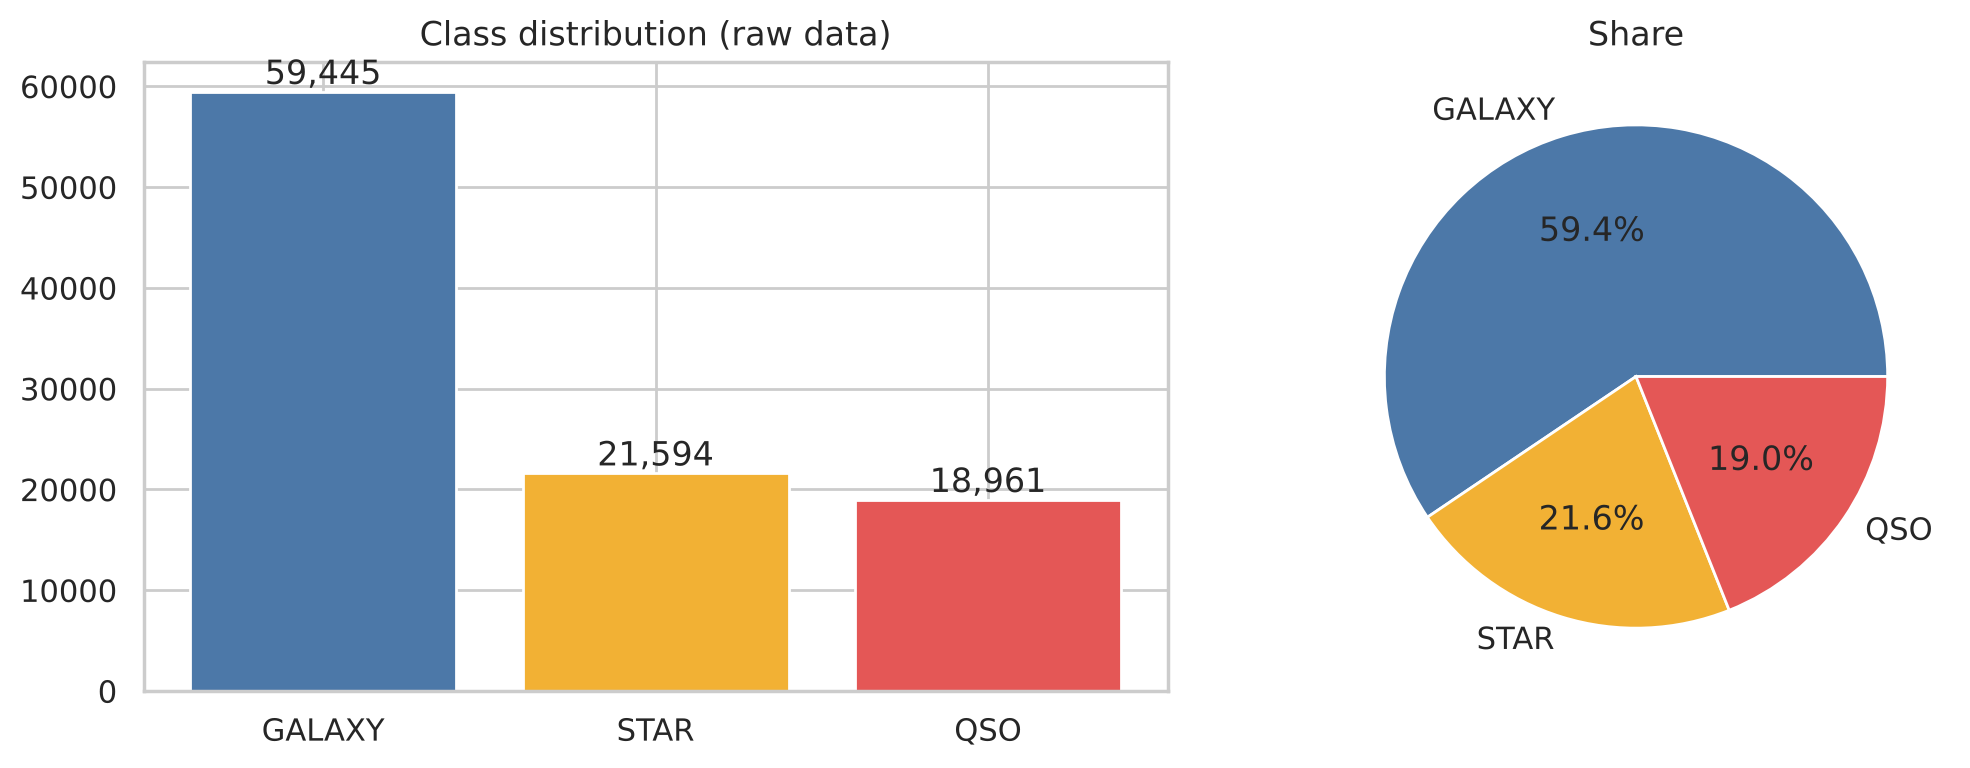

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
cnt = raw["class"].value_counts()
ax[0].bar(cnt.index, cnt.values, color=[PALETTE[c] for c in cnt.index]); ax[0].set_title("Class distribution (raw data)")
for i, v in enumerate(cnt.values): ax[0].text(i, v, f"{v:,}", ha="center", va="bottom")
ax[1].pie(cnt.values, labels=cnt.index, autopct="%1.1f%%", colors=[PALETTE[c] for c in cnt.index]); ax[1].set_title("Share")
show("class_distribution.png")

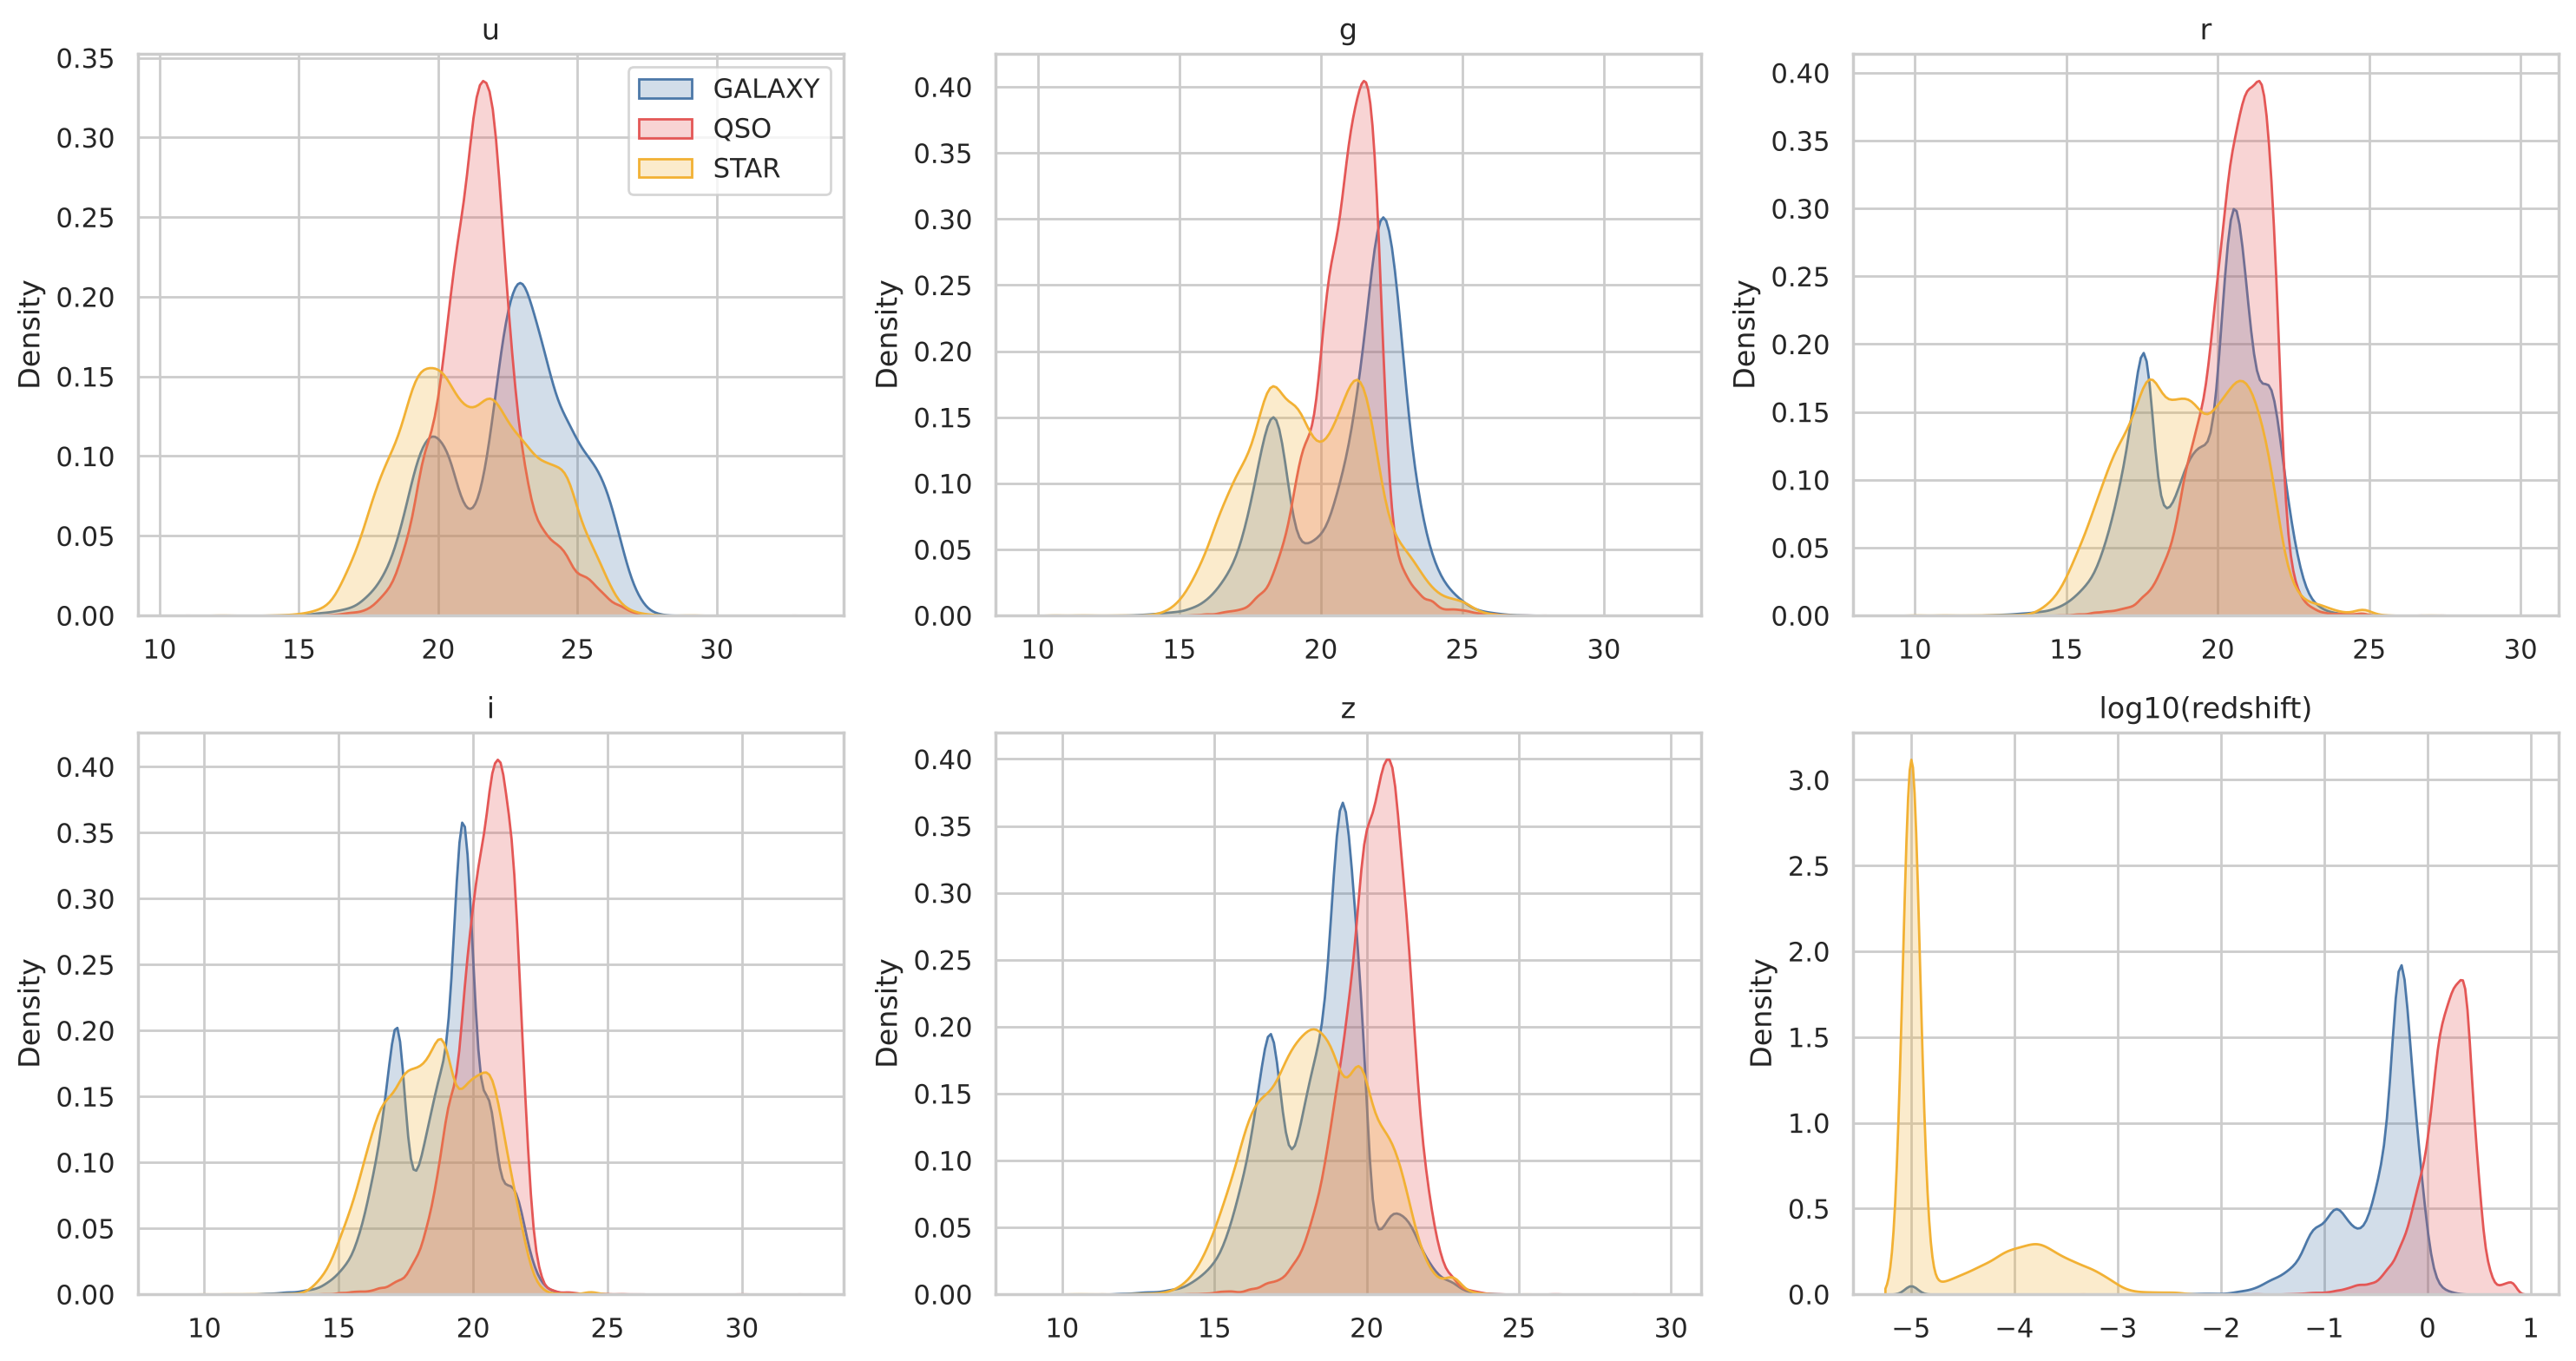

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, f in zip(axes.ravel(), MAGS + ["redshift"]):
    for c in CLASSES:
        x = df.loc[df["class"] == c, f]
        if f == "redshift": x = np.log10(x.clip(lower=1e-5))
        sns.kdeplot(x, ax=ax, label=c, color=PALETTE[c], fill=True, alpha=.25, common_norm=False)
    ax.set_title(f if f != "redshift" else "log10(redshift)"); ax.set_xlabel("")
axes[0, 0].legend(); show("feature_distributions.png")

**Reading:** the magnitude distributions of the three classes overlap heavily (top row) - brightness alone cannot identify an object. On the log-redshift panel the **stars pile up at the lowest redshifts, quasars extend to the highest**, with galaxies in between: the single most discriminating variable, which anticipates the large drop we will see when it is removed.

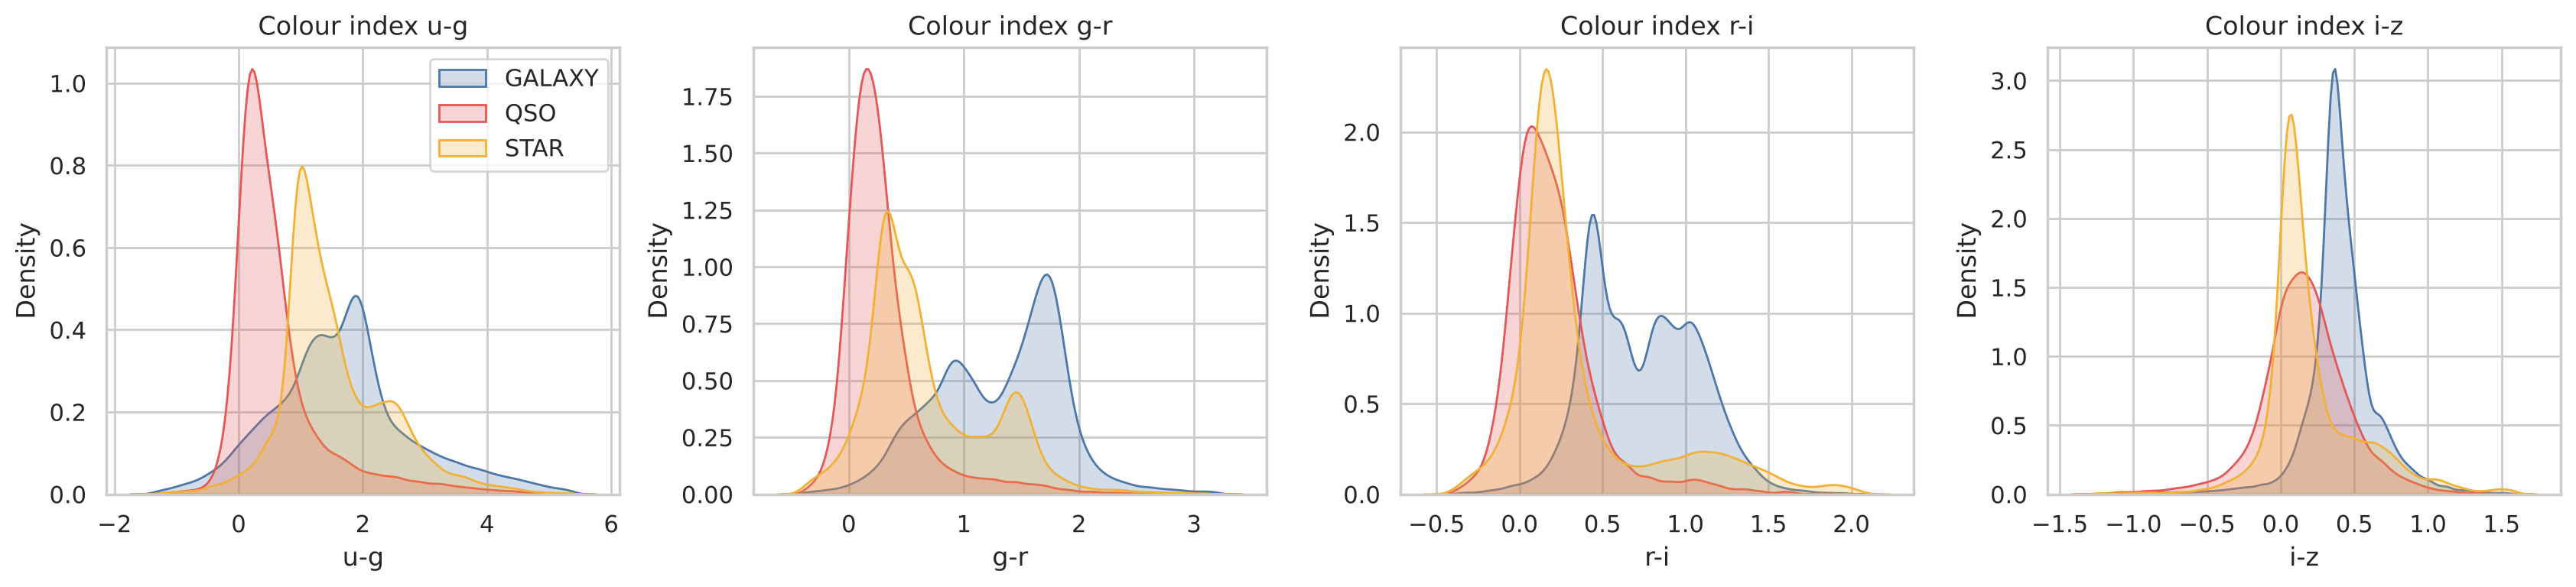

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, f in zip(axes, COLORS):
    lo, hi = df[f].quantile([.005, .995])
    for c in CLASSES:
        sns.kdeplot(df.loc[(df["class"] == c) & df[f].between(lo, hi), f], ax=ax, label=c, color=PALETTE[c], fill=True, alpha=.25, common_norm=False)
    ax.set_title(f"Colour index {f}")
axes[0].legend(); show("color_distributions.png")

**Reading:** the engineered colours separate the classes better than the raw magnitudes did - especially `u-g` (quasars are bluer in the ultraviolet) and `g-r`/`r-i` (stars form a distinct stellar locus). The overlap that remains, mostly between quasars and stars/galaxies, is the part that makes the problem non-trivial.

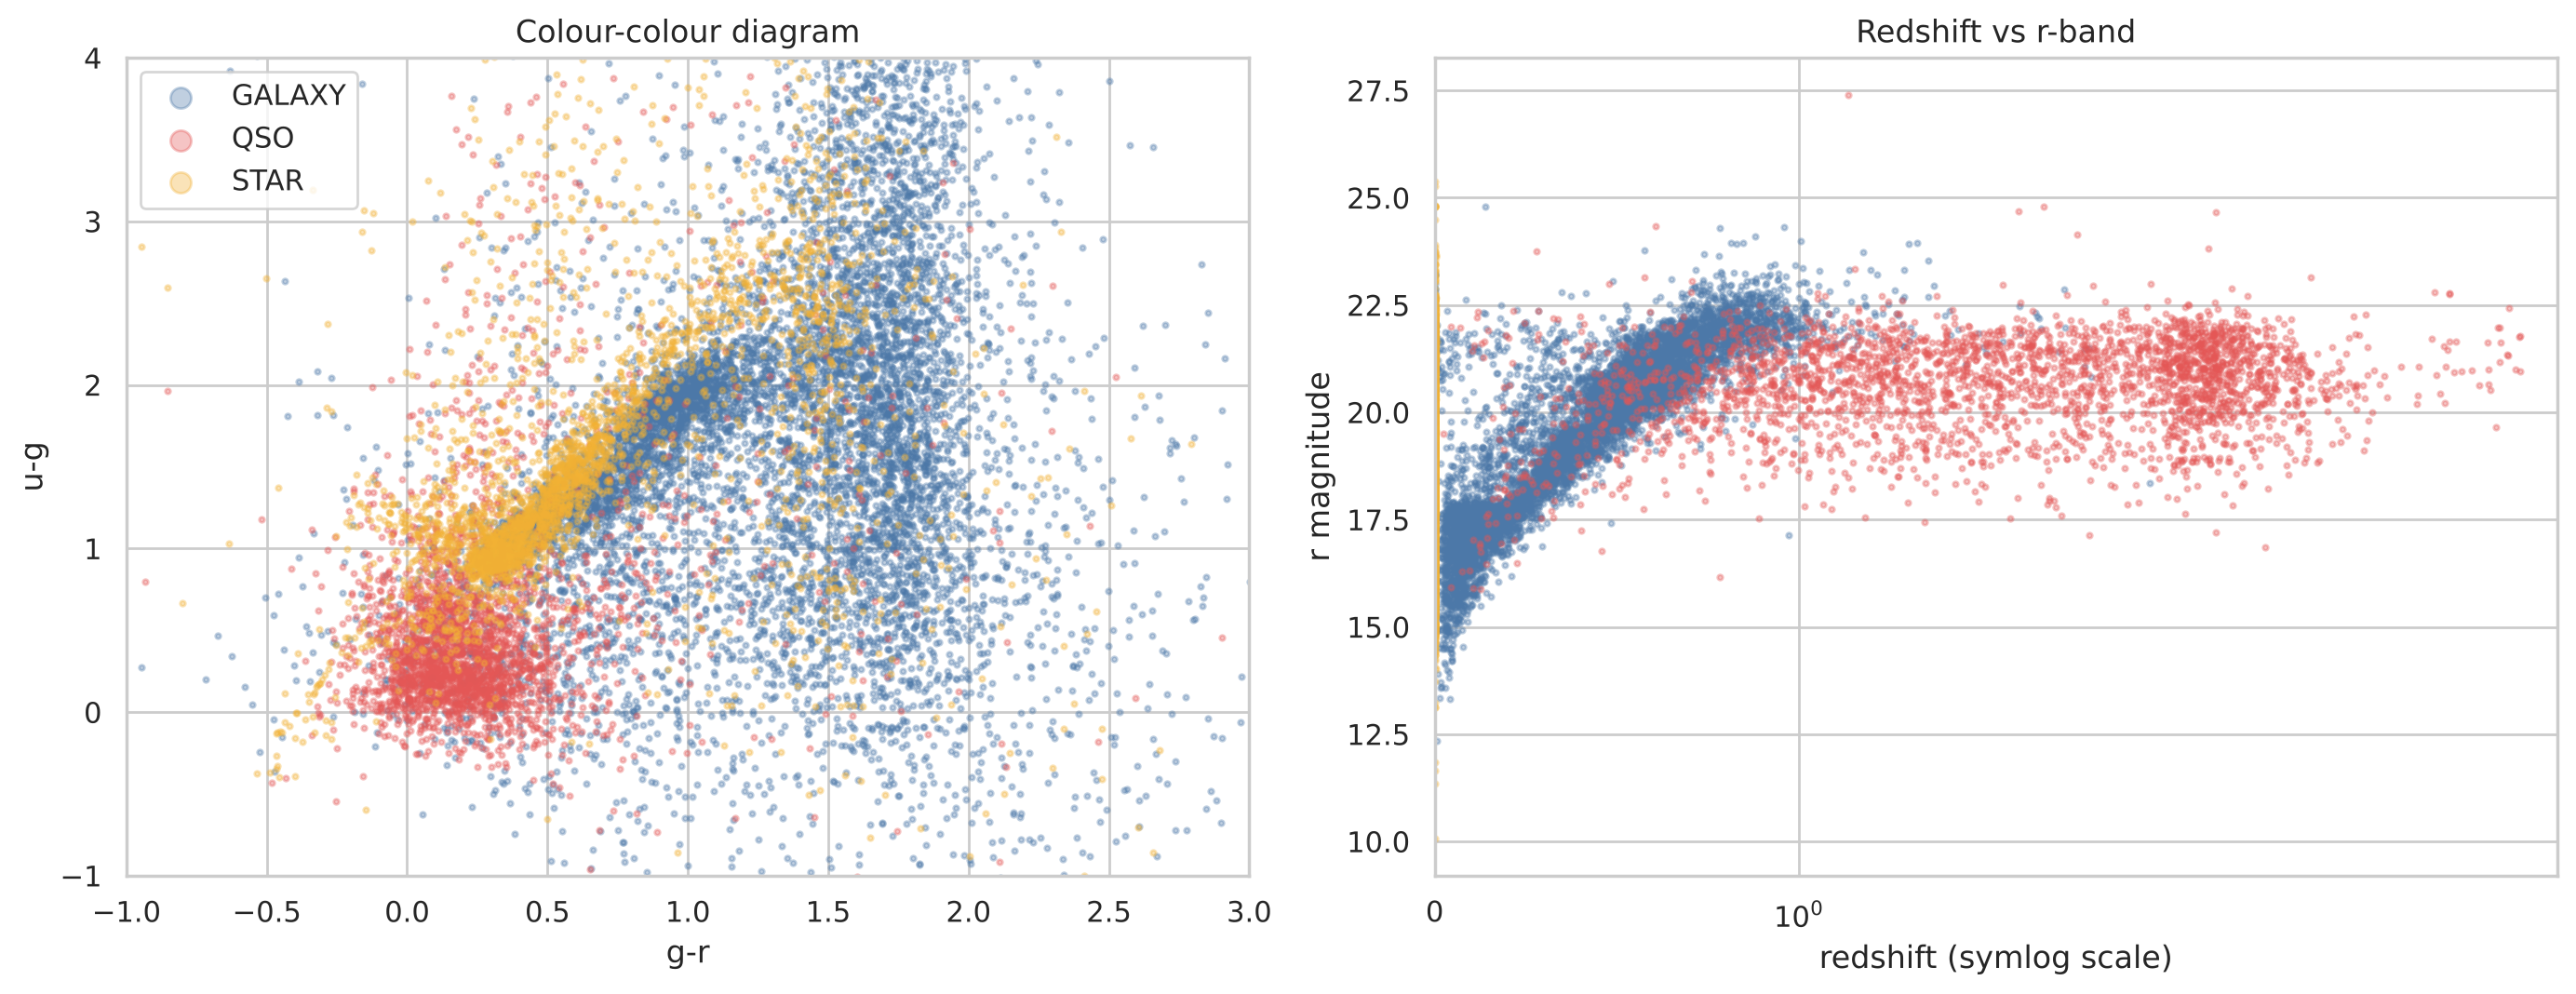

In [11]:
s = df.sample(15000, random_state=SEED)
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for c in CLASSES:
    d = s[s["class"] == c]
    ax[0].scatter(d["g-r"], d["u-g"], s=4, alpha=.35, color=PALETTE[c], label=c)
    ax[1].scatter(d["redshift"], d["r"], s=4, alpha=.35, color=PALETTE[c], label=c)
ax[0].set(xlabel="g-r", ylabel="u-g", title="Colour-colour diagram", xlim=(-1, 3), ylim=(-1, 4))
ax[1].set(xlabel="redshift (symlog scale)", ylabel="r magnitude", title="Redshift vs r-band", xscale="symlog", xlim=(-1e-3, 8))
ax[0].legend(markerscale=4); show("color_color_redshift.png")

**Reading:** in the colour-colour diagram (left) the classes occupy partly separate regions with a zone of overlap; in the redshift panel (right) the classes are separated almost into vertical bands - *redshift does most of the work*, colours resolve what is left.

## 8. Correlations

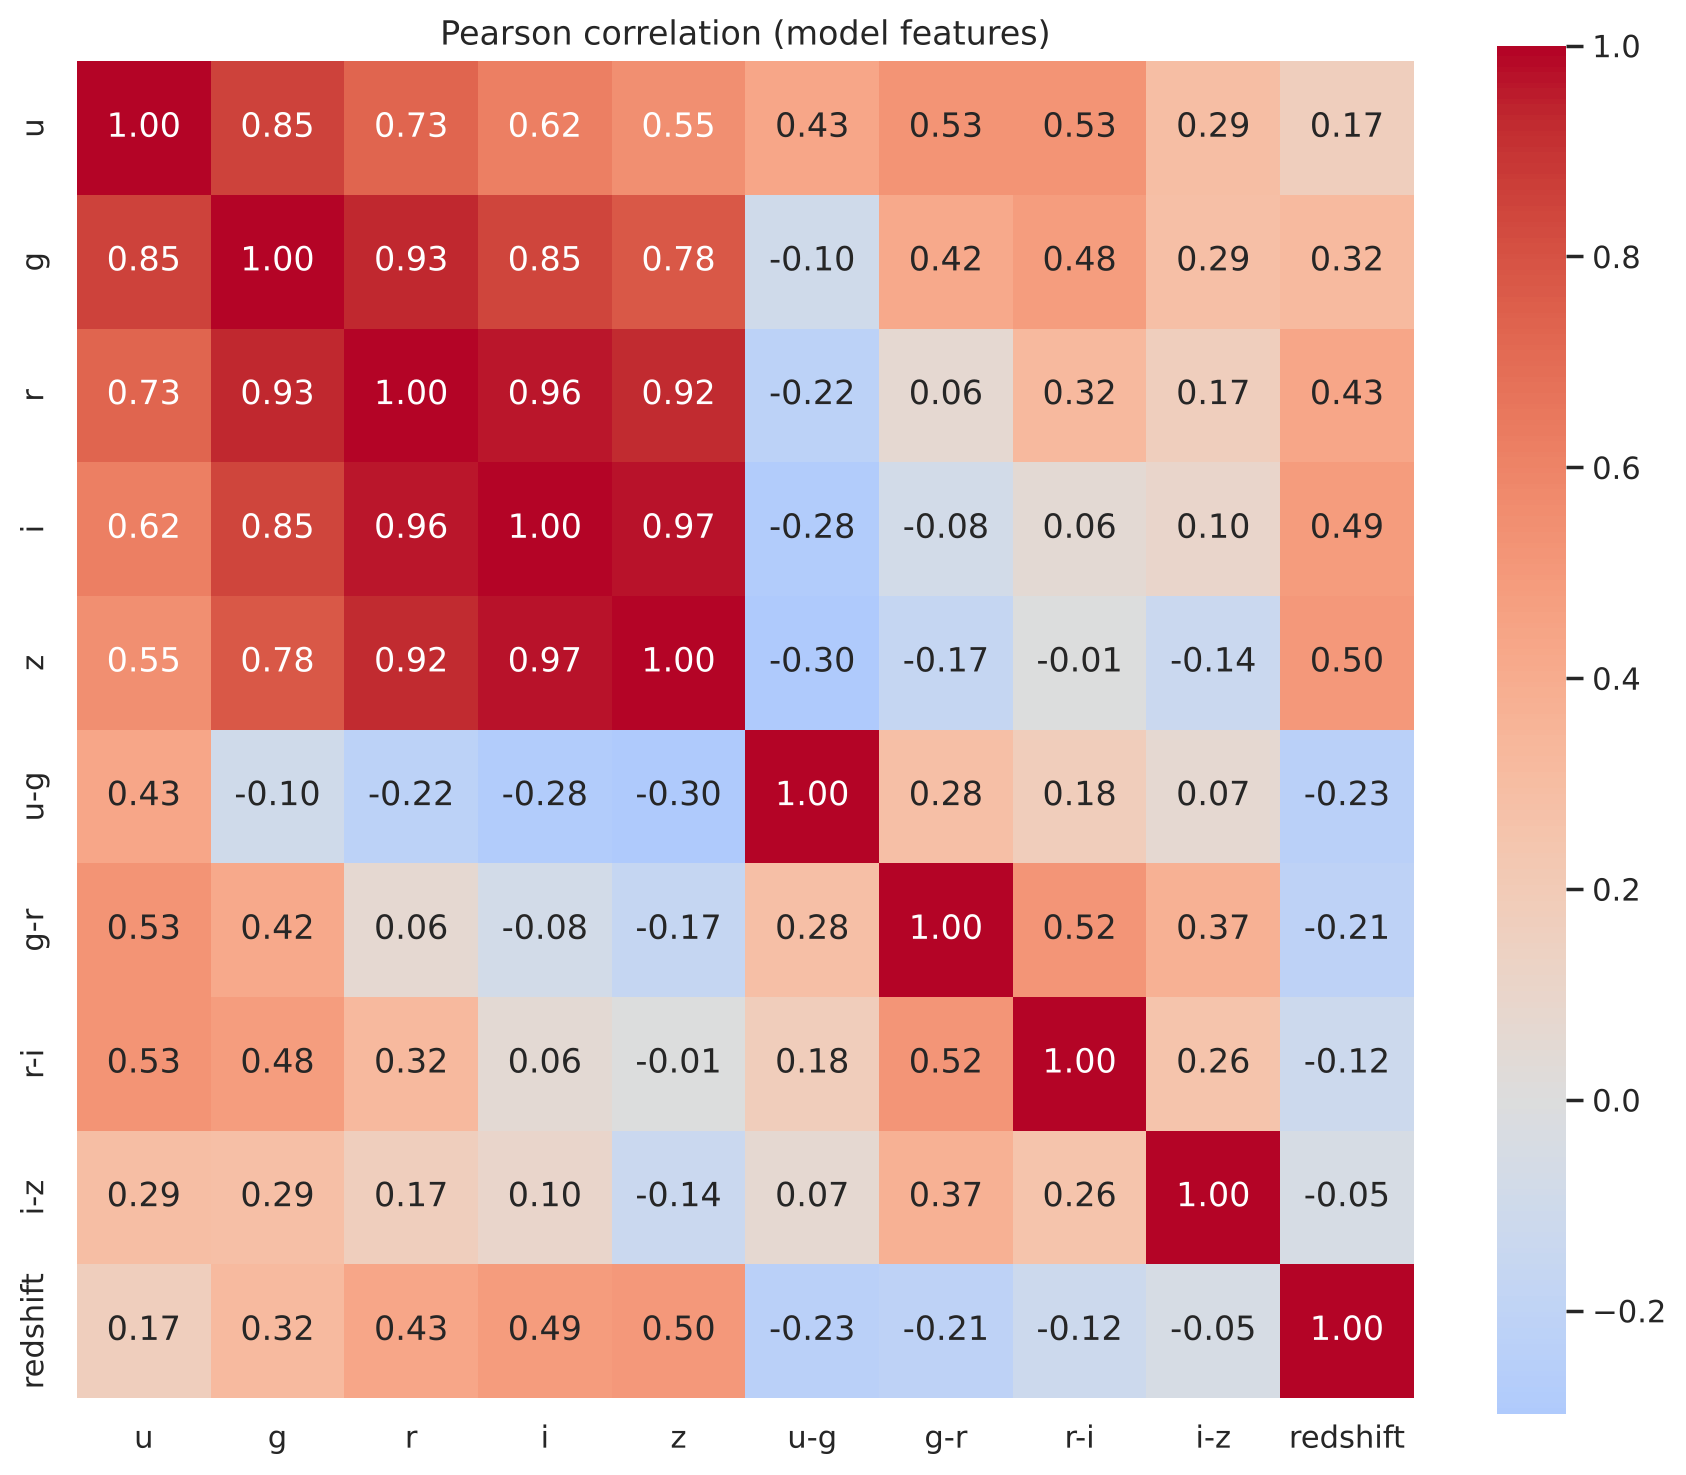

In [12]:
plt.figure(figsize=(9, 7.5))
sns.heatmap(df[feats].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Pearson correlation (model features)"); show("correlation.png")

**Reading:** the five magnitudes are almost perfectly correlated with one another (they all track overall brightness) - redundancy that the **colour indices remove**, since differences cancel the shared brightness. Redshift is only weakly correlated with the photometry, i.e. it brings *new* information, which is why it matters so much. Tree models are not hurt by correlated inputs, so we keep both magnitudes and colours.

## 9. Outliers
IQR rule (beyond 1.5 x IQR from the quartiles), overall and per class.

,feature,n_outliers,pct,pct_GALAXY,pct_QSO,pct_STAR
0,u,55,0.06,0.03,0.02,0.15
1,g,98,0.10,0.11,0.03,0.12
2,r,132,0.13,0.15,0.02,0.17
3,i,198,0.20,0.25,0.07,0.15
4,z,319,0.32,0.42,0.09,0.25
5,u-g,3219,3.22,4.58,0.85,1.54
6,g-r,509,0.51,0.58,0.24,0.56
7,r-i,908,0.91,0.38,0.33,2.86
8,i-z,5102,5.10,4.10,5.62,7.40
9,redshift,8989,8.99,0.06,47.23,0.00


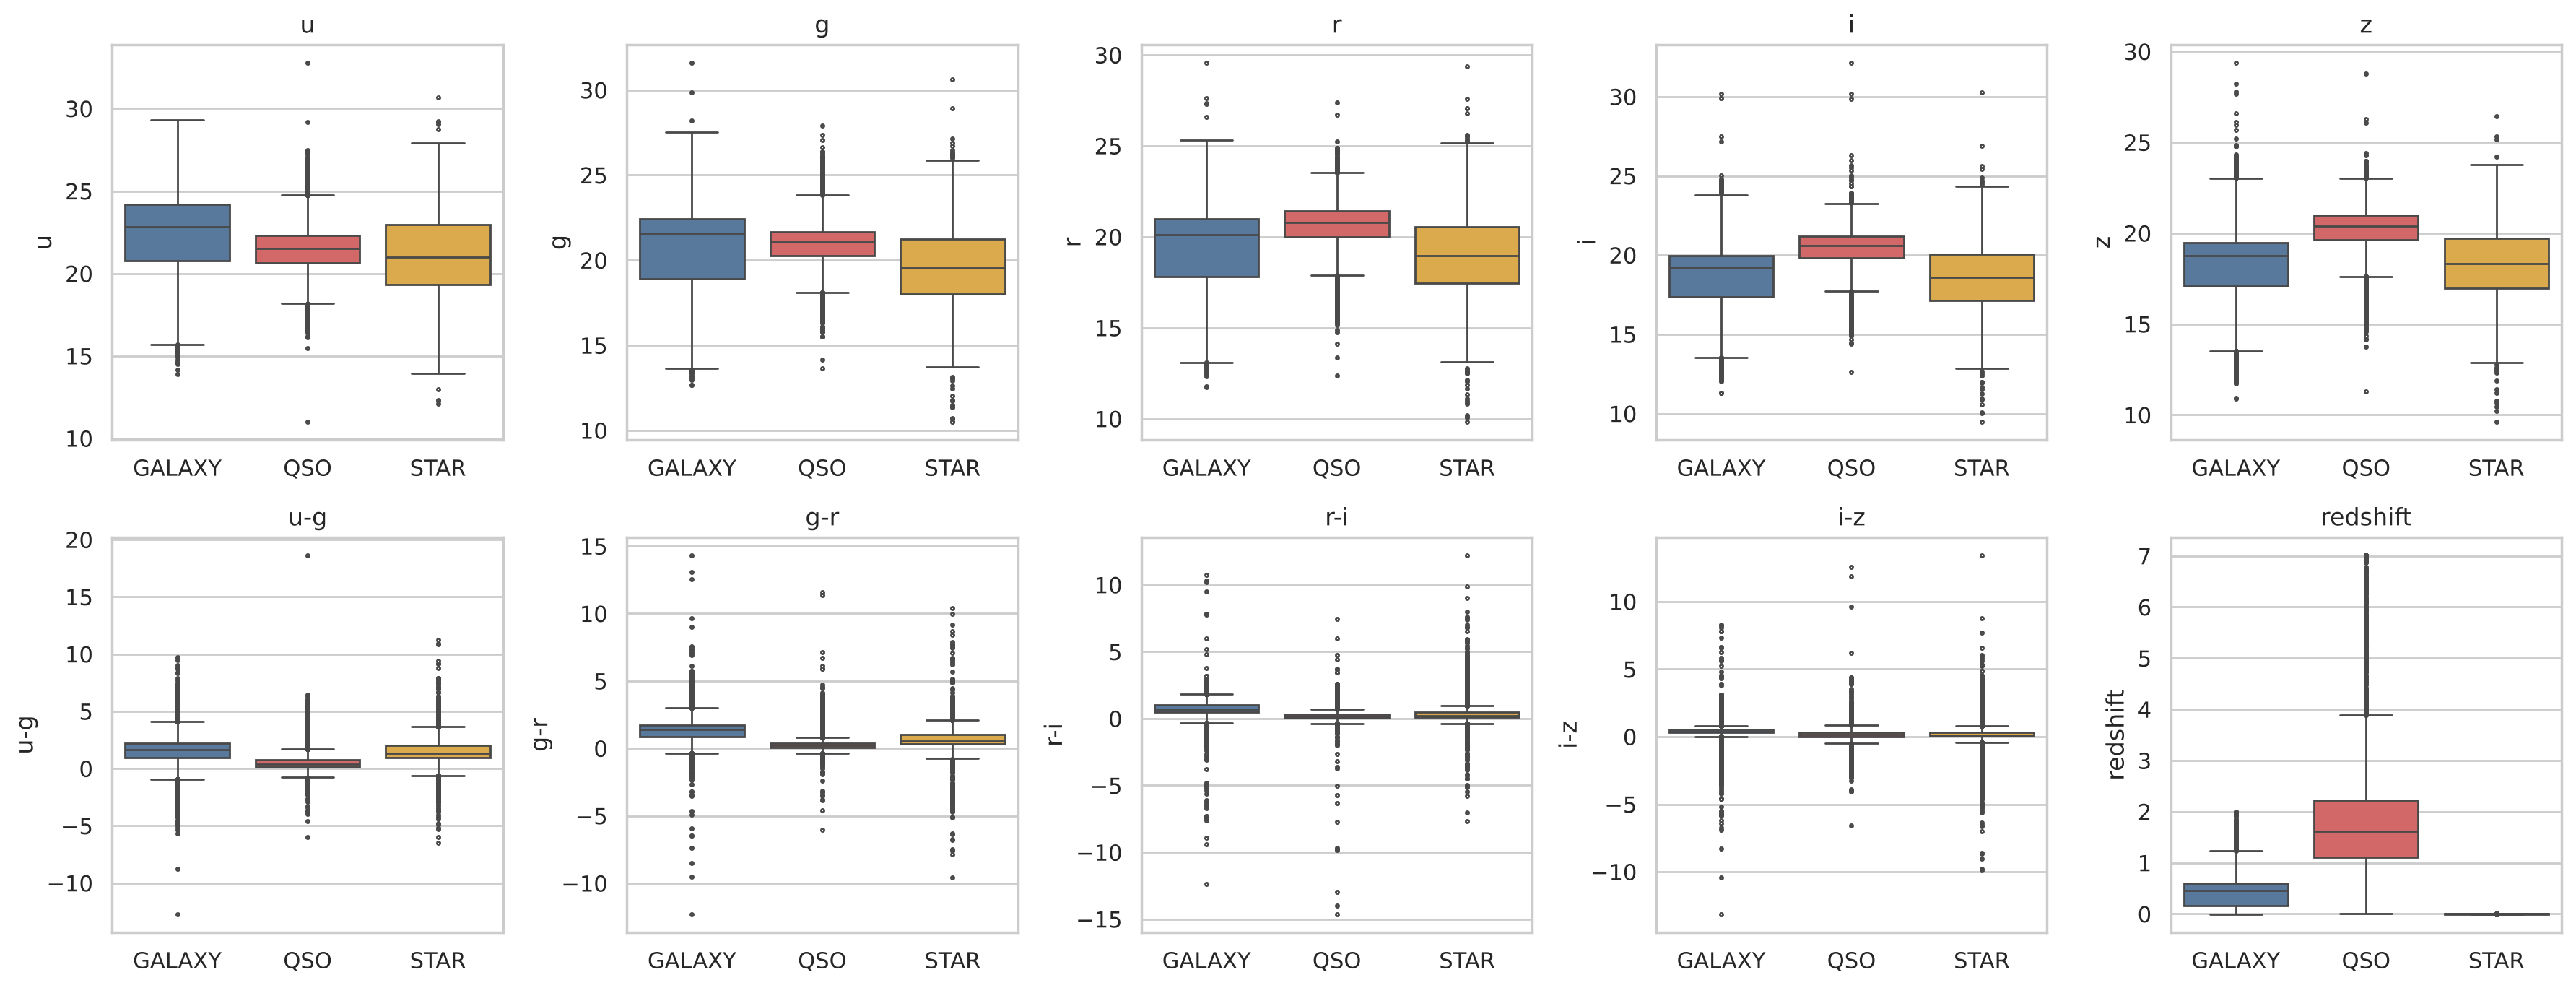

In [13]:
orows = []
for f in feats:
    q1, q3 = df[f].quantile([.25, .75]); iqr = q3 - q1
    m = (df[f] < q1 - 1.5 * iqr) | (df[f] > q3 + 1.5 * iqr)
    orows.append({"feature": f, "n_outliers": int(m.sum()), "pct": round(100 * m.mean(), 2),
                  **{f"pct_{c}": round(100 * m[df["class"] == c].mean(), 2) for c in CLASSES}})
out_tab = pd.DataFrame(orows); out_tab.to_csv(OUT / "outliers_iqr.csv", index=False); display(out_tab)

fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for ax, f in zip(axes.ravel(), MAGS + COLORS + ["redshift"]):
    sns.boxplot(data=df, x="class", y=f, order=CLASSES, hue="class", hue_order=CLASSES, palette=PALETTE, legend=False, ax=ax, fliersize=1.5)
    ax.set_title(f); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(OUT / "boxplots_outliers.png", dpi=120); plt.show()

**Reading and decision:** `redshift` has the most outliers by the IQR rule (9 % of rows, and 47 % of the quasars) - but they are *not errors*: they are the high-redshift quasars, genuinely different objects and exactly what the classifier must recognise. **We therefore keep all outliers.** The only true error was the `-9999` sentinel, already removed. Gradient-boosted trees split on thresholds, so extreme values do not distort them the way they would distort linear or distance-based models.

## 10. Save the overview, the app sample and log to MLflow
`overview.json` and `data_sample.csv` (5,000 rows per class) are read by the Streamlit app.

In [14]:
info = {
    "shape": list(raw.shape), "columns": list(raw.columns), "dtypes": {c: str(t) for c, t in raw.dtypes.items()},
    "missing_values_total": int(raw.isna().sum().sum()), "duplicate_rows": int(raw.duplicated().sum()),
    "duplicate_obj_ID": int(raw["obj_ID"].duplicated().sum()), "duplicate_spec_obj_ID": int(raw["spec_obj_ID"].duplicated().sum()),
    "class_counts": raw["class"].value_counts().to_dict(),
    "class_share_pct": (raw["class"].value_counts(normalize=True) * 100).round(2).to_dict(),
    "sentinel_-9999_counts": sentinels, "excluded_identifier_columns": ID_COLS, "excluded_sky_position_columns": SKY_COLS,
    "rows_removed_by_cleaning": n_removed, "rows_after_cleaning": int(len(df)), "split_sizes": sizes,
    "split_class_share_pct": {k: (v["class"].value_counts(normalize=True) * 100).round(2).to_dict() for k, v in splits.items()},
}
(OUT / "overview.json").write_text(json.dumps(info, indent=2))

sample = pd.concat([g.sample(min(len(g), 5000), random_state=SEED) for _, g in df[["class"] + feats].groupby("class")])
sample.to_csv(ART / "data_sample.csv", index=False)

mlflow_experiment("SDSS17-EDA")
with mlflow.start_run(run_name="eda"):
    mlflow.log_params({"rows_raw": raw.shape[0], "rows_after_cleaning": len(df), "n_features_with_redshift": len(feats),
                       "split": "70/15/15 stratified", "seed": SEED})
    mlflow.log_metric("sentinel_rows_removed", n_removed)
    mlflow.log_artifacts(str(OUT), artifact_path="eda")
print("saved overview.json, data_sample.csv and logged the EDA run to MLflow")

2026/11/21 02:10:21 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/21 02:10:21 INFO mlflow.store.db.utils: Updating database tables


saved overview.json, data_sample.csv and logged the EDA run to MLflow


## Summary of findings
1. Clean dataset: no missing values/duplicates; one `-9999` row removed.
2. Classes are imbalanced (59 / 22 / 19 %) -> use **Macro-F1** and stratified splits.
3. **Redshift is the dominant feature**; colour indices add the rest; raw magnitudes are redundant with each other.
4. Outliers are mostly real high-redshift quasars -> kept.
5. Split: 69,999 / 15,000 / 15,000 stratified rows, shared by all later notebooks.